In [405]:
import pandas as pd

df = pd.read_csv('../data/dataset.csv')

In [406]:
# _____________________<( Columns )>___________________________
df_columns = df.columns
print(df_columns)
# ['Unnamed: 0', 'Pregnancies', 'Glucose', 'BloodPressure','SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Index(['Unnamed: 0', 'Pregnancies', 'Glucose', 'BloodPressure',
       'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')


In [407]:
# _____________________<( DF Shape )>__________________________
print(df.shape) #(768, 9)

(768, 9)


In [408]:
# _____________________<( exemple de data )>___________________
print(df.head(3))
#    Unnamed: 0  Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age
# 0           0            6      148             72             35        0  33.6                     0.627   50
# 1           1            1       85             66             29        0  26.6                     0.351   31
# 2           2            8      183             64              0        0  23.3                     0.672   32


   Unnamed: 0  Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin  \
0           0            6      148             72             35        0   
1           1            1       85             66             29        0   
2           2            8      183             64              0        0   

    BMI  DiabetesPedigreeFunction  Age  
0  33.6                     0.627   50  
1  26.6                     0.351   31  
2  23.3                     0.672   32  


In [409]:
# _____________________<( identifier les doublons )>___________________
dupl_sum = df.duplicated().sum()
print(f'nombre des doubons : {dupl_sum}')
# nombre des doubons : 0


nombre des doubons : 0


In [410]:
# _____________________<( identifier null values )>___________________
null_values = df.isna().sum()
print(f'null values in each column : {null_values}')


null values in each column : Unnamed: 0                  0
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


In [411]:
# _____________________<( columns data type )>___________________
column_type = df.dtypes
print(f'columns types : {column_type}')


columns types : Unnamed: 0                    int64
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
dtype: object


In [412]:
# _____________________<( drop the index column )>___________________
df = df.drop(columns=['Unnamed: 0'])

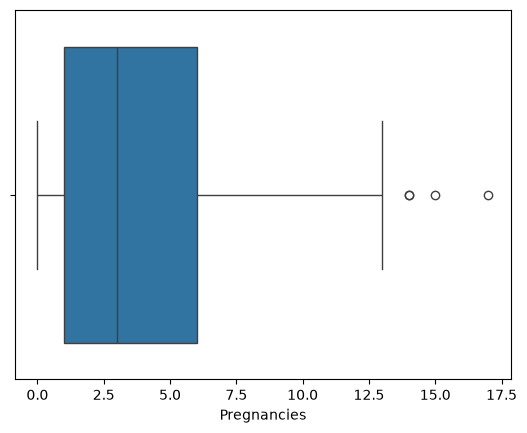

In [413]:
# _____________________<( search for outliers )>___________________
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Pregnancies'])
plt.show()

# note : no outliers here

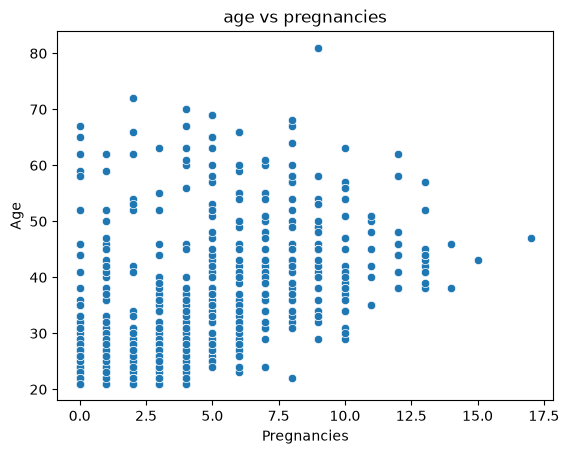

In [414]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Pregnancies'], y=df['Age'])
plt.xlabel('Pregnancies')
plt.ylabel('Age')
plt.title('age vs pregnancies')
plt.show()

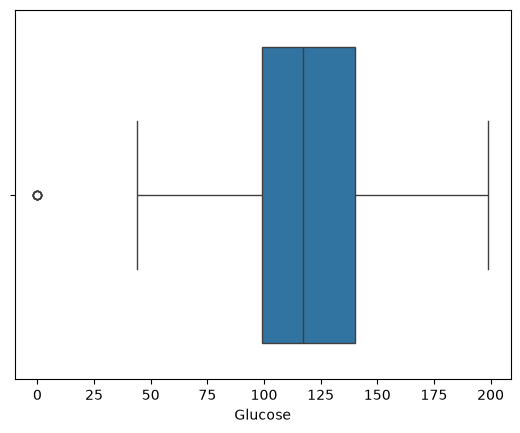

In [415]:
# _____________________<( search for outliers )>___________________
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Glucose'])
plt.show()

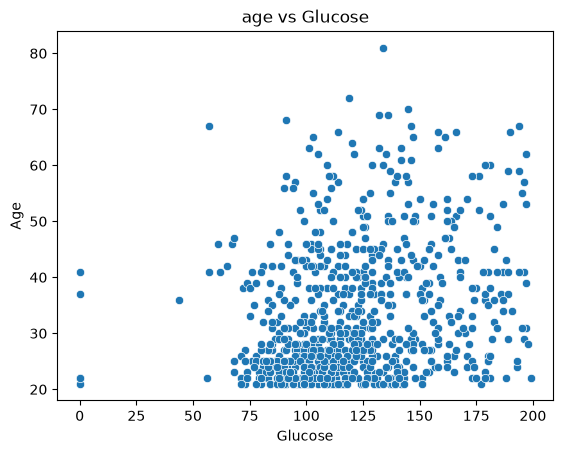

In [416]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Glucose'], y=df['Age'])
plt.xlabel('Glucose')
plt.ylabel('Age')
plt.title('age vs Glucose')
plt.show()

## replacing the invalide 0 values using KNN

In [417]:
from sklearn.impute import KNNImputer
import numpy as np

features_0 = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction']
features = df.columns
imputer = KNNImputer(n_neighbors=5)
for col in features_0 :
    df.loc[df[col] == 0, col] = np.nan
df[features] = imputer.fit_transform(df[features])


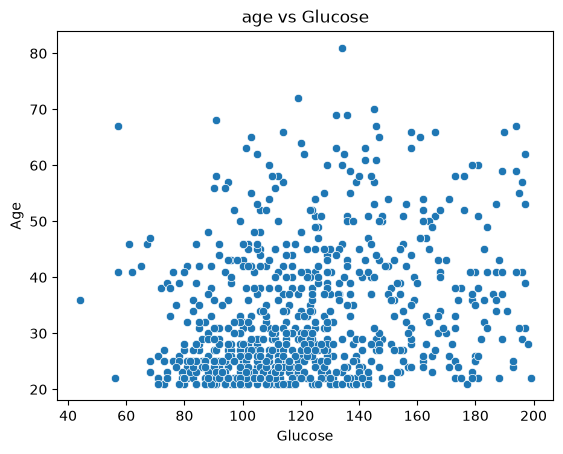

In [418]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Glucose'], y=df['Age'])
plt.xlabel('Glucose')
plt.ylabel('Age')
plt.title('age vs Glucose')
plt.show()

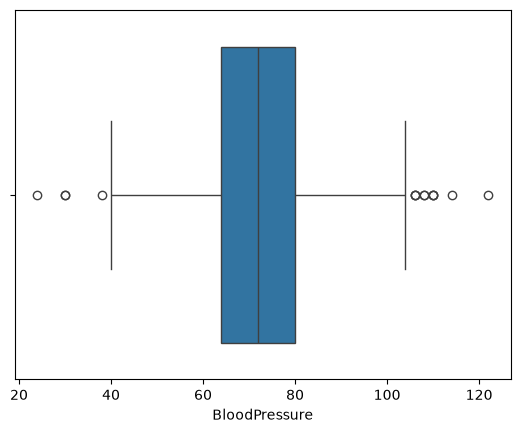

In [419]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['BloodPressure'])
plt.show()

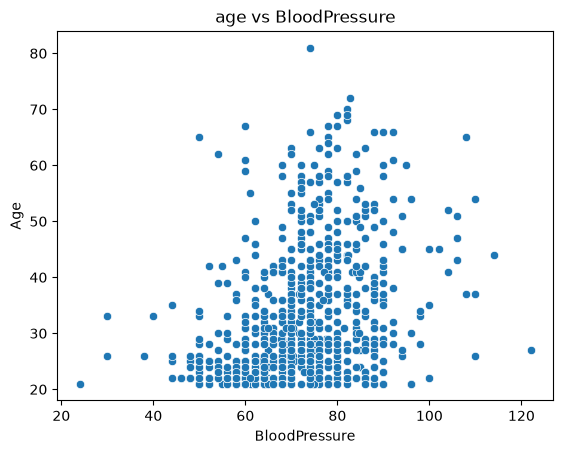

In [420]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BloodPressure'], y=df['Age'])
plt.xlabel('BloodPressure')
plt.ylabel('Age')
plt.title('age vs BloodPressure')
plt.show()

In [421]:
lower_bound = df['BloodPressure'].quantile(0.005)
upper_bound = df['BloodPressure'].quantile(0.997)

df['BloodPressure'] = df['BloodPressure'].clip(lower = lower_bound, upper=upper_bound)

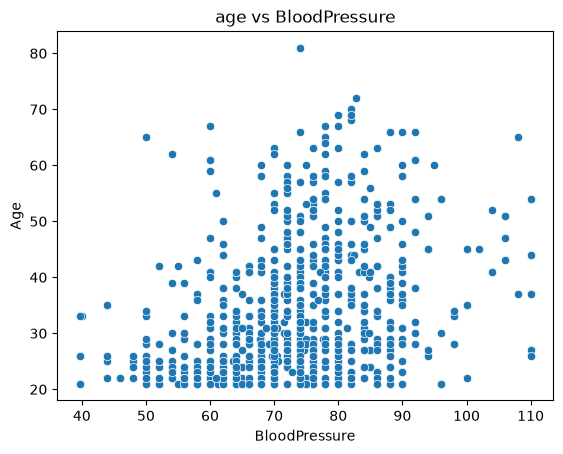

In [422]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BloodPressure'], y=df['Age'])
plt.xlabel('BloodPressure')
plt.ylabel('Age')
plt.title('age vs BloodPressure')
plt.show()

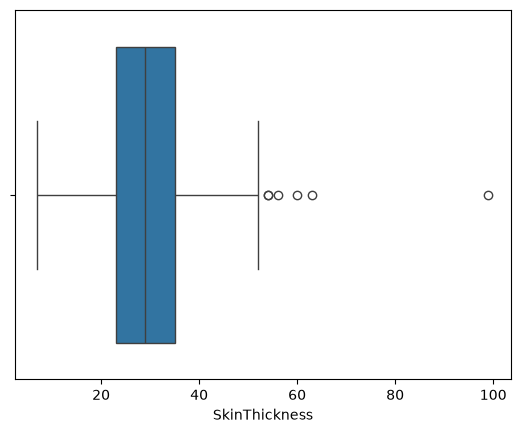

In [423]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['SkinThickness'])
plt.show()

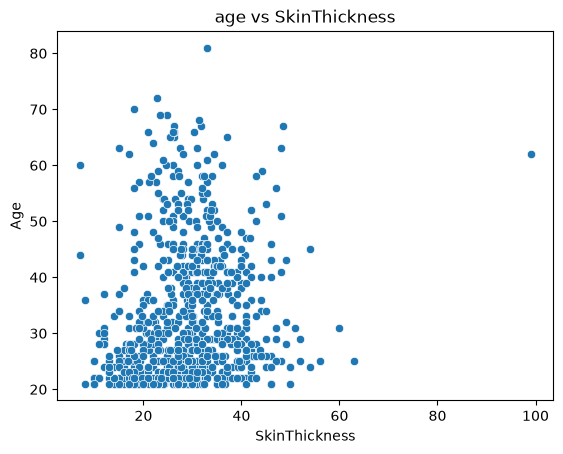

In [424]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['SkinThickness'], y=df['Age'])
plt.xlabel('SkinThickness')
plt.ylabel('Age')
plt.title('age vs SkinThickness')
plt.show()

In [425]:
upper_bound = df["SkinThickness"].quantile(0.995)

df["SkinThickness"] = df["SkinThickness"].clip(upper=upper_bound)

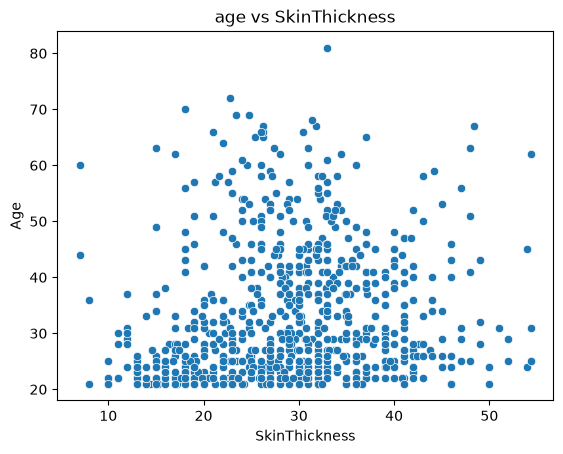

In [426]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['SkinThickness'], y=df['Age'])
plt.xlabel('SkinThickness')
plt.ylabel('Age')
plt.title('age vs SkinThickness')
plt.show()

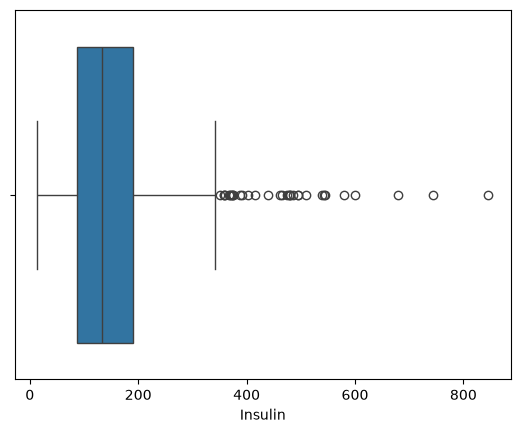

In [427]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['Insulin'])
plt.show()



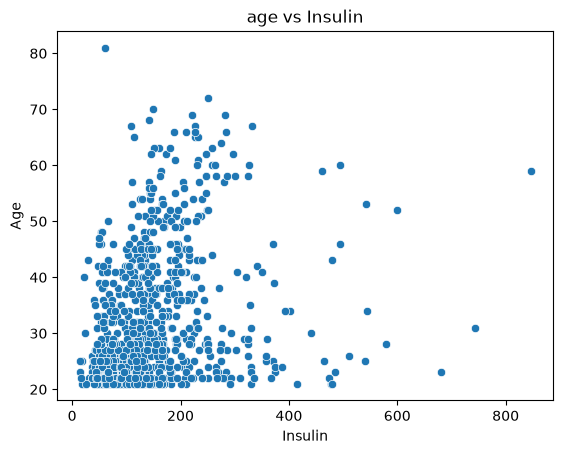

In [428]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Insulin'], y=df['Age'])
plt.xlabel('Insulin')
plt.ylabel('Age')
plt.title('age vs Insulin')
plt.show()

In [429]:
print(df[df['Insulin'] > 600])

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
13           1.0    189.0           60.0           23.0    846.0  30.1   
228          4.0    197.0           70.0           39.0    744.0  36.7   
247          0.0    165.0           90.0           33.0    680.0  52.3   

     DiabetesPedigreeFunction   Age  
13                      0.398  59.0  
228                     2.329  31.0  
247                     0.427  23.0  


In [430]:
print(f'rows with insulin = 0 : {(df["Insulin"] == 0).sum()}')

rows with insulin = 0 : 0


In [431]:
upper_bound = df["Insulin"].quantile(0.996)

df["Insulin"] = df["Insulin"].clip(upper=upper_bound)

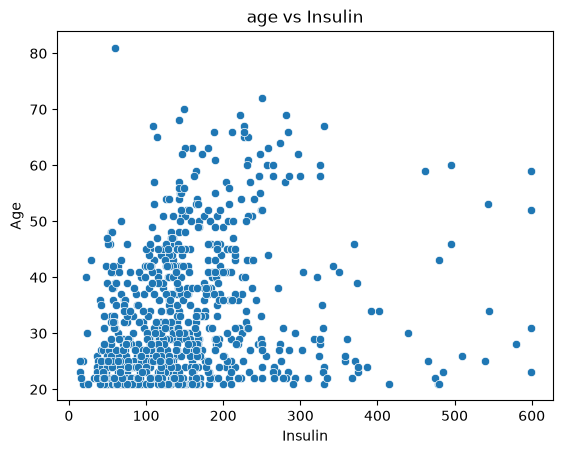

In [432]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['Insulin'], y=df['Age'])
plt.xlabel('Insulin')
plt.ylabel('Age')
plt.title('age vs Insulin')
plt.show()

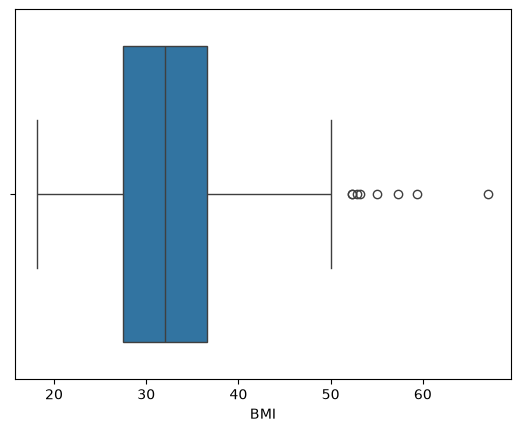

In [433]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x=df['BMI'])
plt.show()

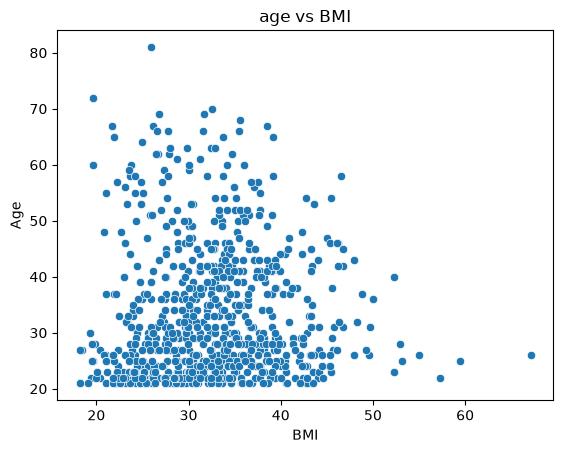

In [434]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BMI'], y=df['Age'])
plt.xlabel('BMI')
plt.ylabel('Age')
plt.title('age vs BMI')
plt.show()

In [435]:
upper_bound = df["BMI"].quantile(0.995)

df["BMI"] = df["BMI"].clip(upper=upper_bound)

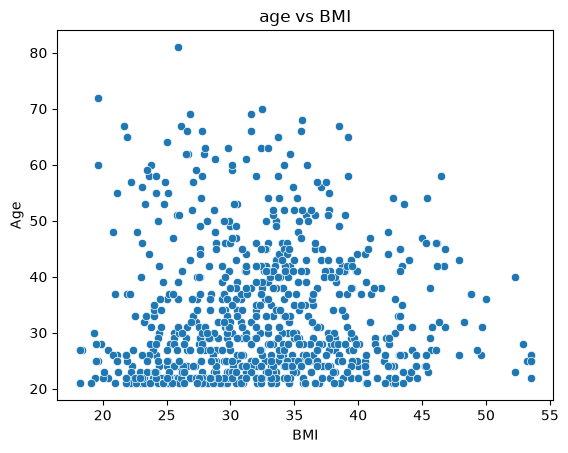

In [436]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['BMI'], y=df['Age'])
plt.xlabel('BMI')
plt.ylabel('Age')
plt.title('age vs BMI')
plt.show()

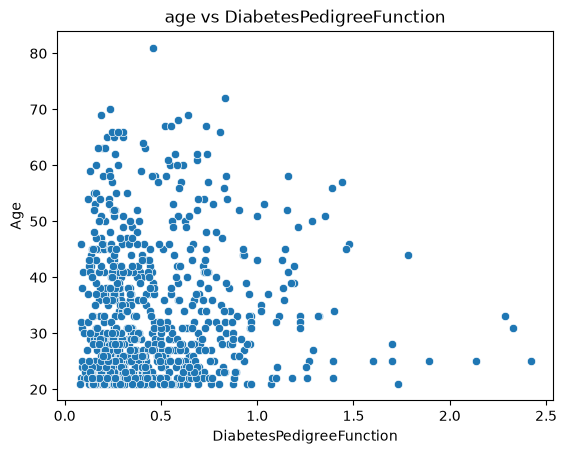

In [437]:
import matplotlib.pyplot as plt

sns.scatterplot(x=df['DiabetesPedigreeFunction'], y=df['Age'])
plt.xlabel('DiabetesPedigreeFunction')
plt.ylabel('Age')
plt.title('age vs DiabetesPedigreeFunction')
plt.show()

In [438]:
print(df[df['DiabetesPedigreeFunction'] > 2.0])

     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
4            0.0    137.0           40.0          35.00  168.000  43.100   
228          4.0    197.0           70.0          39.00  598.572  36.700   
370          3.0    173.0           82.0          48.00  465.000  38.400   
445          0.0    180.0           78.0          54.33   14.000  53.497   

     DiabetesPedigreeFunction   Age  
4                       2.288  33.0  
228                     2.329  31.0  
370                     2.137  25.0  
445                     2.420  25.0  


In [439]:
for col in df.columns:
    print(f"Max de {col} : {df[col].max()}")
    print(f"Min de {col} : {df[col].min()}")
    print()

Max de Pregnancies : 17.0
Min de Pregnancies : 0.0

Max de Glucose : 199.0
Min de Glucose : 44.0

Max de BloodPressure : 110.0
Min de BloodPressure : 39.67

Max de SkinThickness : 54.32999999999993
Min de SkinThickness : 7.0

Max de Insulin : 598.5720000000003
Min de Insulin : 14.0

Max de BMI : 53.496999999999936
Min de BMI : 18.2

Max de DiabetesPedigreeFunction : 2.42
Min de DiabetesPedigreeFunction : 0.078

Max de Age : 81.0
Min de Age : 21.0



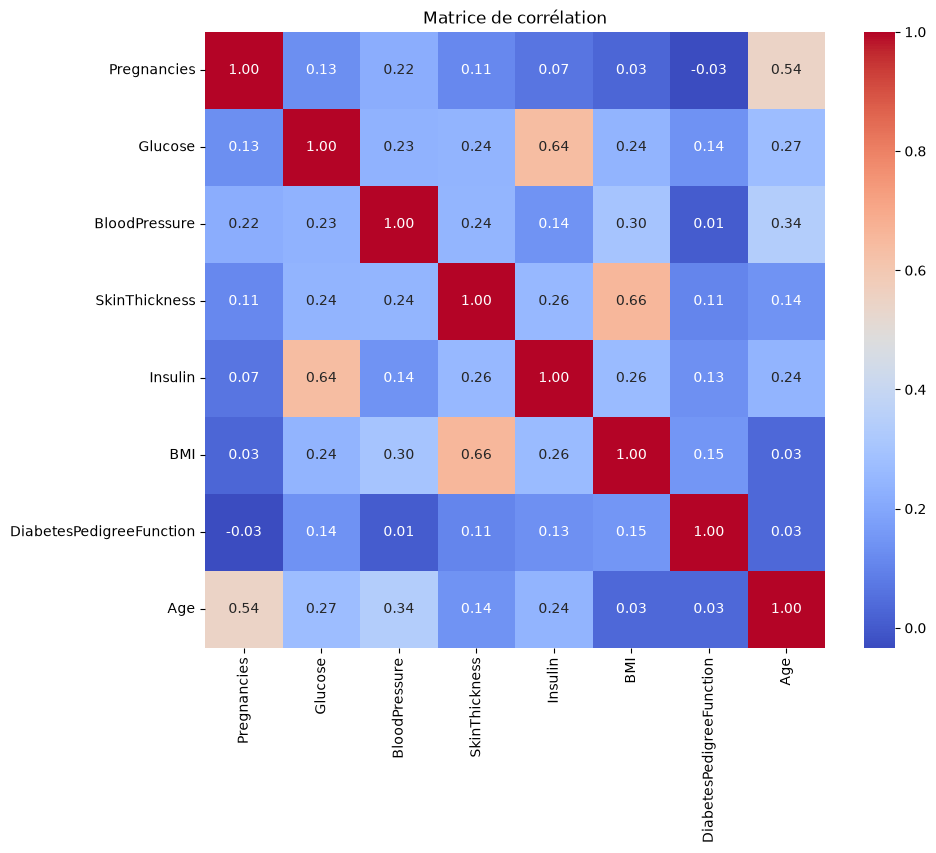

In [440]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matrice de corrélation")
plt.show()

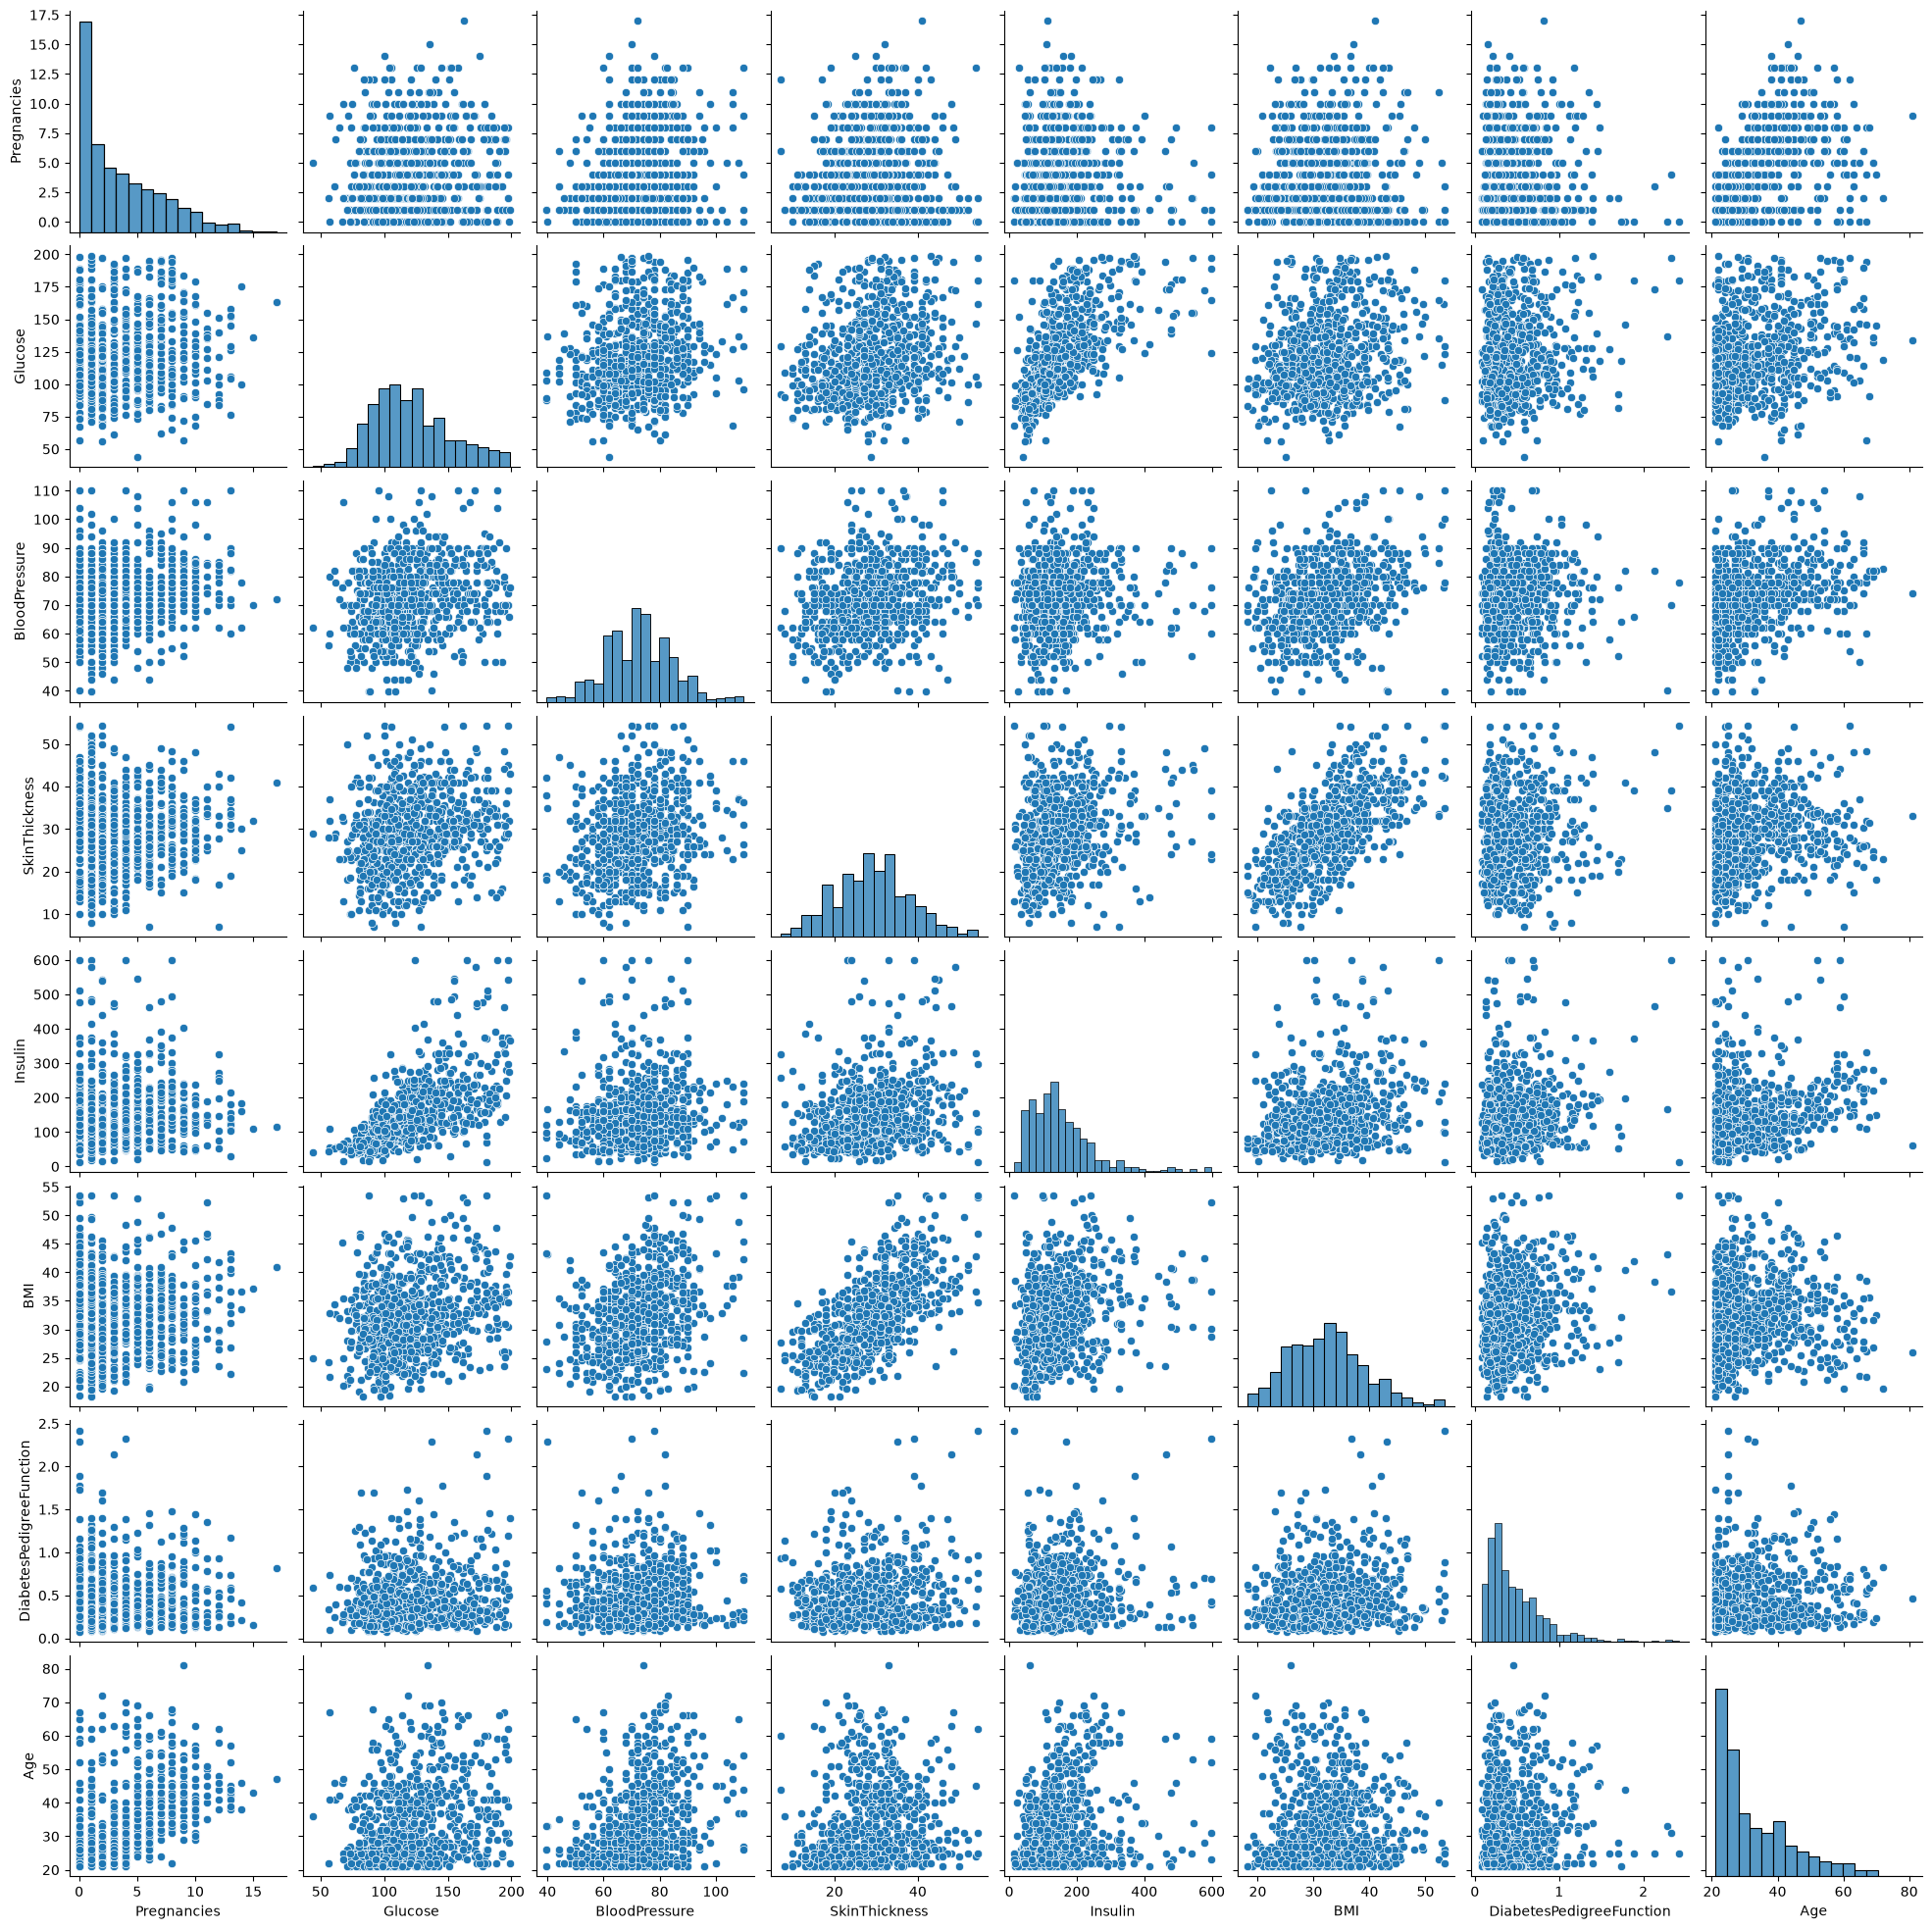

In [441]:
import seaborn as sns
import matplotlib.pyplot as plt

features = df.columns
sns.pairplot(df[features])
plt.show()


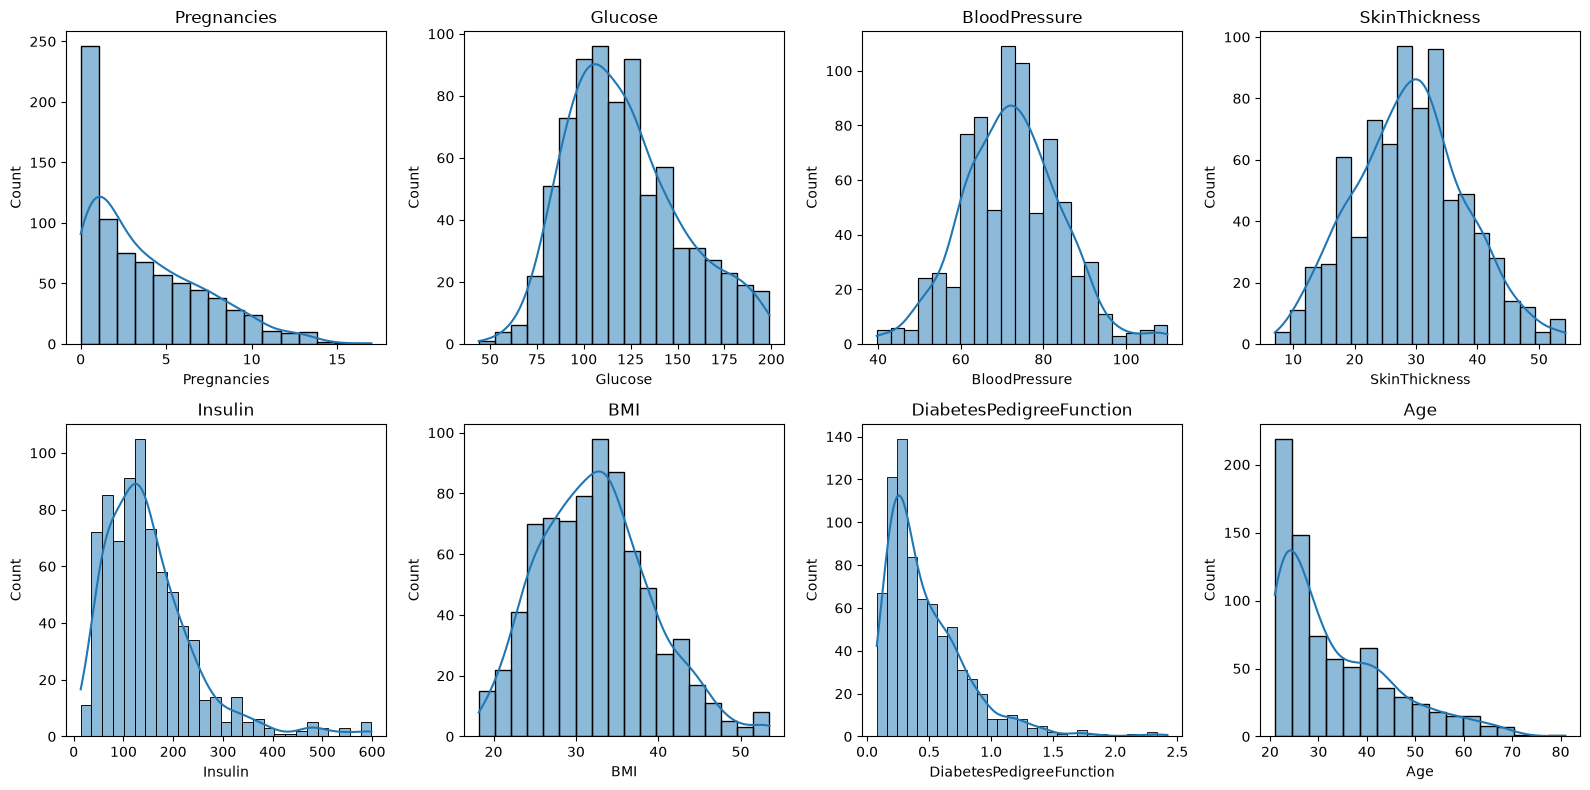

In [442]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, df.columns):
    sns.histplot(df[col], ax=ax, kde=True)
    ax.set_title(col)
plt.tight_layout()

In [443]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_scaler = scaler.fit_transform(df)

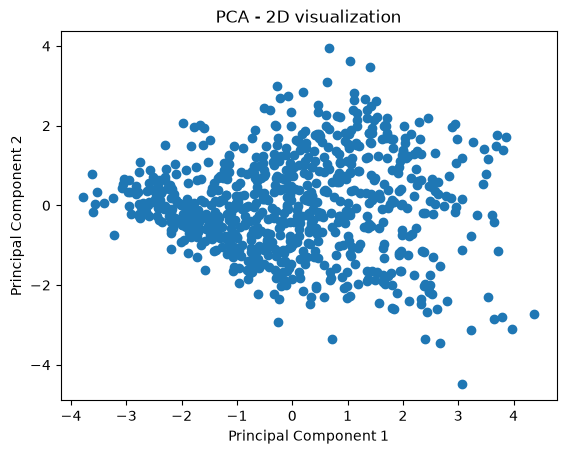

In [444]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(x_scaler)

import matplotlib.pyplot as plt

plt.scatter(X_pca[:, 0], X_pca[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D visualization")

plt.show()

[0.21405436637596834, 0.20338944959424046, 0.18017551634480636, 0.1535599994685832, 0.15457965538507457]
5


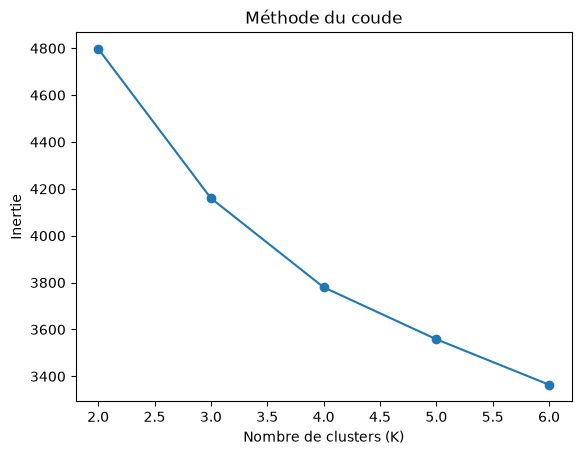

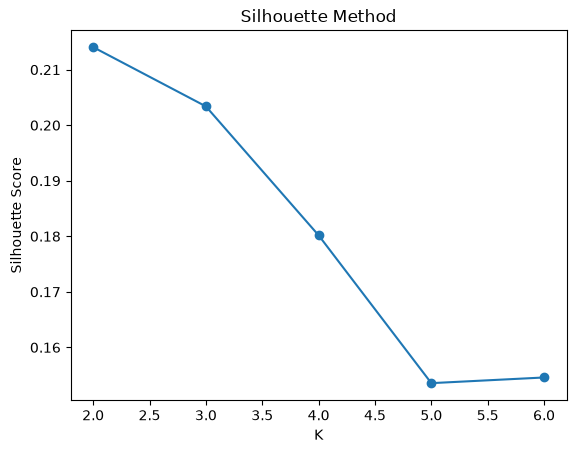

In [445]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


inertias = []
silhouette_scores = []


for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    # kmeans.fit(df[numeric_cols])
    labels = kmeans.fit_predict(x_scaler)
    
    inertias.append(kmeans.inertia_)
    score = silhouette_score(x_scaler, labels)
    silhouette_scores.append(score)

print(silhouette_scores)
print(len(silhouette_scores))


# elbow
plt.plot(range(2, 7), inertias, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.show()

# silouhaitte
plt.plot(range(2, 7), silhouette_scores, marker='o')
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")

plt.show()

In [446]:
# from sklearn.cluster import KMeans
# from sklearn.metrics import silhouette_score

# results = {}

# for k in [2, 3]:
#     kmeans = KMeans(
#         n_clusters=k,
#         random_state=42,
#         n_init=10
#     )

#     labels = kmeans.fit_predict(x_scaler)

#     inertia = kmeans.inertia_
#     silhouette = silhouette_score(x_scaler, labels)

#     results[k] = {
#         "model": kmeans,
#         "labels": labels,
#         "inertia": inertia,
#         "silhouette": silhouette
#     }

#     print(f"K = {k}")
#     print(f"Inertia: {inertia:.2f}")
#     print(f"Silhouette Score: {silhouette:.3f}")

In [447]:
print(df.head(4))

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0          6.0    148.0           72.0           35.0    169.0  33.6   
1          1.0     85.0           66.0           29.0     58.6  26.6   
2          8.0    183.0           64.0           25.8    164.6  23.3   
3          1.0     89.0           66.0           23.0     94.0  28.1   

   DiabetesPedigreeFunction   Age  
0                     0.627  50.0  
1                     0.351  31.0  
2                     0.672  32.0  
3                     0.167  21.0  


| Column                       | What it measures                                             | Typical unit / metric           |
| ------------------------ | ------------------------------------------------------------ | ----------------------------|
| Pregnancies              | Number of times the person has been pregnant                 | Count                       |    |
| Glucose                  | Plasma glucose concentration                                 | mg/dL                       |
| BloodPressure            | Diastolic blood pressure                                     | mmHg                        |
| SkinThickness            | Triceps skin-fold thickness                                  | mm                          |
| Insulin                  | 2-hour serum insulin                                         | μU/mL (also written µIU/mL) |
| BMI                      | Body Mass Index                                              | kg/m²                       |
| DiabetesPedigreeFunction | A measure related to family history/genetic risk of diabetes | Unitless score              |
| Age                      | Age of the patient                                           | Years                       |

c:\Users\ycode\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


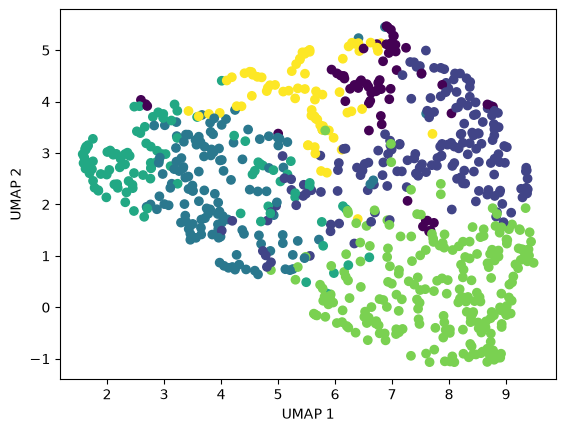

In [448]:
from umap import UMAP
import matplotlib.pyplot as plt

umap = UMAP(n_components=2, random_state=42)

X_umap = umap.fit_transform(x_scaler)

plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels)
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.show()

In [449]:
print(df.columns)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='str')


In [450]:
# _____________________<( columns data type )>___________________
column_type = df.dtypes
print(f'columns types : {column_type}')

columns types : Pregnancies                 float64
Glucose                     float64
BloodPressure               float64
SkinThickness               float64
Insulin                     float64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                         float64
dtype: object


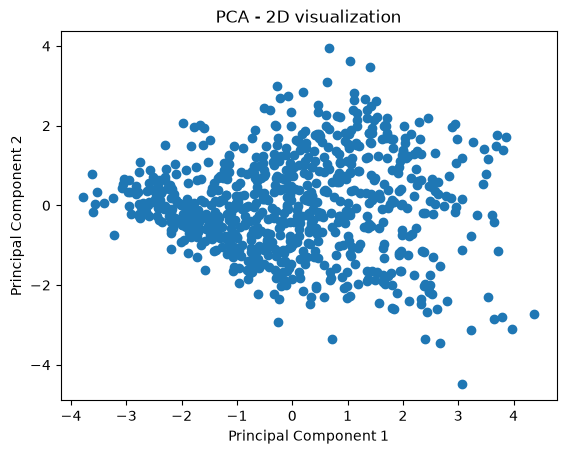

In [451]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(x_scaler)

import matplotlib.pyplot as plt

plt.scatter(X_pca[:, 0], X_pca[:, 1])

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - 2D visualization")

plt.show()

In [452]:
# from sklearn.cluster import KMeans
# import matplotlib.pyplot as plt
# from sklearn.metrics import silhouette_score


# inertias = []
# silhouette_scores = []


# for k in range(2, 11):
#     kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
#     # kmeans.fit(df[numeric_cols])
#     labels = kmeans.fit_predict(df)
    
#     inertias.append(kmeans.inertia_)
#     score = silhouette_score(x_scaler, labels)
#     silhouette_scores.append(score)

# print(silhouette_scores)
# print(len(silhouette_scores))


# # elbow
# plt.plot(range(2, 11), inertias, marker='o')
# plt.xlabel("Nombre de clusters (K)")
# plt.ylabel("Inertie")
# plt.title("Méthode du coude")
# plt.show()

# # silouhaitte
# plt.plot(range(2, 11), silhouette_scores, marker='o')
# plt.xlabel("K")
# plt.ylabel("Silhouette Score")
# plt.title("Silhouette Method")

# plt.show()

In [453]:
# from umap import UMAP
# import matplotlib.pyplot as plt

# umap = UMAP(n_components=2, random_state=42)

# X_umap = umap.fit_transform(df)

# plt.scatter(X_umap[:, 0], X_umap[:, 1], c=labels)
# plt.xlabel("UMAP 1")
# plt.ylabel("UMAP 2")
# plt.show()

In [455]:
import pandas as pd

df.to_csv('../data/cleaned_data.csv')